In [1]:
import warnings
warnings.filterwarnings('ignore')
import Bio
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

In [2]:
selection_dir = '../analysis/selection_values/'
output_dir = '../analysis/output_figures/'

In [3]:
# Read in dfs with wtaav2 and rep7868 selection values
wtaav2_selection_barcode_df = pd.read_csv(selection_dir + 'wtaav2_selection_values_barcode.csv')
rep7868_selection_barcode_df = pd.read_csv(selection_dir + 'rep7868_selection_values_barcode.csv')

In [4]:
# Separate replicate selection values into different rows
wt_df_melt = wtaav2_selection_barcode_df.melt(value_vars=['a', 'b'], id_vars=['abs_pos', 'aa', 'codon', 'lib_type', 'barcode', 'is_wt'], value_name='enrichment', var_name='rep')

rep7868_df_melt = rep7868_selection_barcode_df.melt(value_vars=['a', 'b'], id_vars=['abs_pos', 'aa', 'codon', 'lib_type', 'barcode', 'is_wt'], value_name='enrichment', var_name='rep')
rep7868_df_melt

,abs_pos,aa,codon,lib_type,barcode,is_wt,rep,enrichment
0,1,*,TAA,del,GTGAGACTGACACACTGTCT,0,a,0.471768
1,1,*,TAA,del,TCAGACTCTGACTGAGACAG,0,a,0.928537
2,1,*,TAA,sub,ACTGAGAGAGTGACAGACTG,0,a,0.609253
3,1,*,TAA,sub,TCTGAGTCTCACACTCACAG,0,a,0.497817
4,1,*,TAG,sub,GACACTCAGAGAGACTGAGT,0,a,0.442826
...,...,...,...,...,...,...,...,...
161923,622,W,TGG,sub,TCTGACACACTGACACTGAC,0,b,0.787785
161924,622,Y,TAC,sub,CTGAGTGTCAGACTGACTCA,0,b,1.056134
161925,622,Y,TAC,sub,TCAGTGTGTGACAGACTGTC,0,b,0.628245
161926,622,Y,TAT,sub,AGACAGACACAGTGTCTCTG,0,b,0.000000


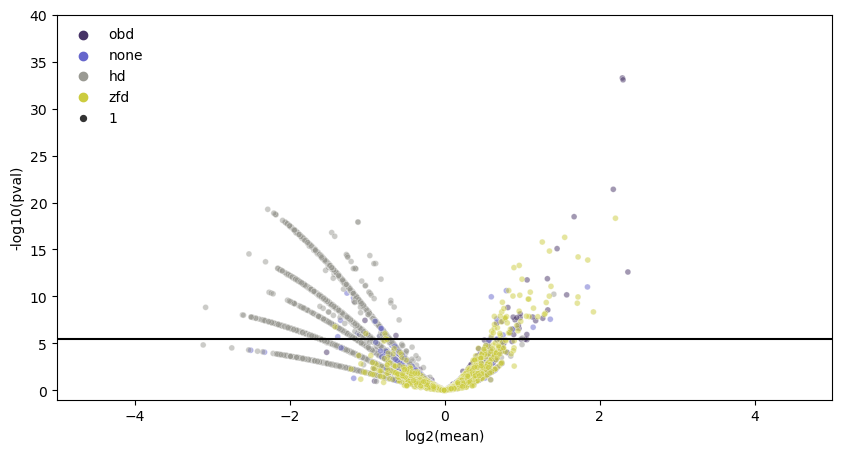

In [6]:
wt_values = wt_df_melt.query('is_wt==1')['enrichment'].values

# For each amino acid variant, calculate p-values from t-test comparing the means of all synonymous replicates vs.
# mean of wild-type controls
# Also report mean selection value for all synonymous replicates
pval = lambda x: stats.ttest_ind(wt_values, x)[1]
pvals = wt_df_melt.groupby(['abs_pos','aa'])['enrichment'].agg([pval, 'mean'])

# Calculate alpha using Bonferroni correction (given number of comparison tests performed)
pvals.columns = ['pval', 'mean']
pvals['1/pval'] = 1 / pvals['pval']
pvals['inverse_pval_bonferroni'] = pvals['1/pval'] / len(pvals)
pvals['-log10(pval)'] = np.log10(pvals['pval'])*-1
pvals['log2(mean)'] = np.log2(pvals['mean'])

# Add column indicating domain that each variant is in
domain_list = []
for v, variant in enumerate(pvals.iterrows()):
#     if v > 10: break
    abs_pos = variant[0][0]
    if abs_pos < 199:
        domain_list.append('obd')
    elif abs_pos > 224 and abs_pos < 491:
        domain_list.append('hd')
    elif abs_pos > 535:
        domain_list.append('zfd')
    else:
        domain_list.append('none')
pvals['domain'] = domain_list

# Generate volcano plot of significance (-log10(pvalue)) vs. mean selection value for all amino acid variants
# in the WT AAV2 library
volcano = plt.figure(figsize = (10, 5))

sns.scatterplot(y='-log10(pval)', x='log2(mean)', data=pvals, alpha=0.5, size=1, hue='domain', palette='gist_stern')

plt.xlim([-5, 5])
plt.ylim([-1, 40])
plt.axhline(-1*np.log10(0.05/len(pvals.index)), color='black') # this is what is significant after bonferroni correction
plt.legend(loc='upper left', fontsize=10, frameon=False)
plt.savefig('../analysis/output_figures/20230926_wtaav2_volcano_plot.png')

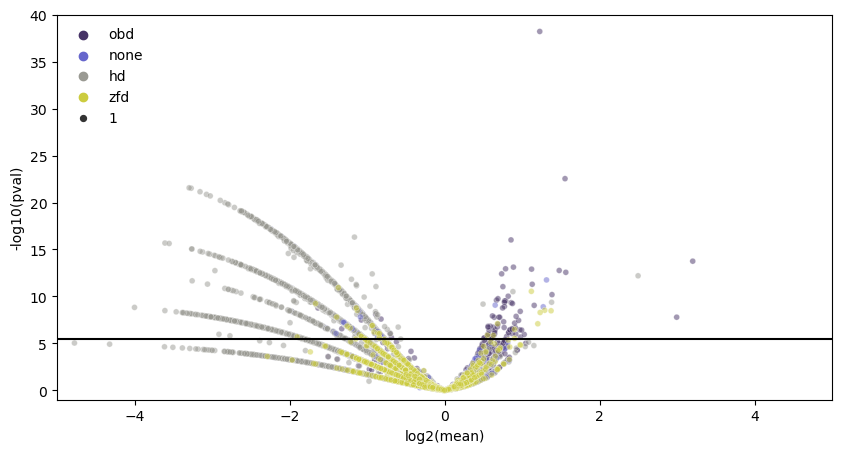

In [7]:
wt_values_rep7868_lib = rep7868_df_melt.query('is_wt==1')['enrichment'].values

# For each amino acid variant, calculate p-values from t-test comparing the means of all synonymous replicates vs.
# mean of wild-type controls
# Also report mean selection value for all synonymous replicates
pval_rep7868 = lambda x: stats.ttest_ind(wt_values_rep7868_lib, x)[1]
pvals_rep7868 = rep7868_df_melt.groupby(['abs_pos','aa'])['enrichment'].agg([pval_rep7868, 'mean'])

# Calculate alpha using Bonferroni correction (given number of comparison tests performed)
pvals_rep7868.columns = ['pval', 'mean']
pvals_rep7868['1/pval'] = 1 / pvals['pval']
pvals_rep7868['inverse_pval_bonferroni'] = pvals_rep7868['1/pval'] / len(pvals_rep7868)
pvals_rep7868['-log10(pval)'] = np.log10(pvals_rep7868['pval'])*-1
pvals_rep7868['log2(mean)'] = np.log2(pvals_rep7868['mean'])

# Add column indicating domain that each variant is in
domain_list = []
for v, variant in enumerate(pvals_rep7868.iterrows()):
#     if v > 10: break
    abs_pos = variant[0][0]
    if abs_pos < 199:
        domain_list.append('obd')
    elif abs_pos > 224 and abs_pos < 491:
        domain_list.append('hd')
    elif abs_pos > 535:
        domain_list.append('zfd')
    else:
        domain_list.append('none')
pvals_rep7868['domain'] = domain_list

# Generate volcano plot of significance (-log10(pvalue)) vs. mean selection value for all amino acid variants
# in the rep7868 library
volcano = plt.figure(figsize = (10, 5))

sns.scatterplot(y='-log10(pval)', x='log2(mean)', data=pvals_rep7868, alpha=0.5, size=1, hue='domain', palette='gist_stern')

plt.xlim([-5, 5])
plt.ylim([-1, 40])
plt.axhline(-1*np.log10(0.05/len(pvals.index)), color='black') # this is what is significant after bonferroni correction
plt.legend(loc='upper left', fontsize=10, frameon=False)
plt.savefig('../analysis/output_figures/20230926_rep7868_volcano_plot.png')